#**1.	Context**

Depressive symptoms may be associated with differences in speaking rate, pauses, pitch, and voice intensity. Researchers therefore study acoustic characteristics of speech as possible supporting information, while recognizing that speech alone does not establish a clinical diagnosis (Almaghrabi et al., 2023).

This lab uses six picture-description WAV files from the public MTSD-S subset: negative, neutral, and positive responses from participant 001 (control) and participant 002 (subthreshold depressive symptoms). The files offer a small example for loading and visualizing speech signals. We calculate RMS amplitude, a smoothed amplitude envelope, and its numerical derivative. Recording conditions and differences between speakers can affect these measures, so the analysis is exploratory.

https://doi.org/10.1016/j.bspc.2023.105020

https://github.com/sixgodgood/MTSD-S-speech-subset

https://doi.org/10.5281/zenodo.22248906

#**2.	Data loading and initial visualization**

In [ ]:
import numpy as np
from scipy.io import wavfile
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

In [ ]:
subjects = ('001', '002')
values = ('negative', 'neutral', 'positive')
wav_files = {}
for subject in subjects:
    for value in values:
        name = f'{subject}_image_{value}.wav'
        path = Path('/content') / name
        url = f'https://raw.githubusercontent.com/sixgodgood/MTSD-S-speech-subset/main/image/{name}'
        wav_files[(subject, value)] = path
        print('Downloaded:', name)

Downloaded: 001_image_negative.wav
Downloaded: 001_image_neutral.wav
Downloaded: 001_image_positive.wav
Downloaded: 002_image_negative.wav
Downloaded: 002_image_neutral.wav
Downloaded: 002_image_positive.wav


/tmp/ipykernel_956/1039250260.py:6: WavFileWarning: Reached EOF prematurely; finished at 527632 bytes, expected 527636 bytes from header.
  fs, raw = wavfile.read(wav_files[(subject, value)])
/tmp/ipykernel_956/1039250260.py:6: WavFileWarning: Reached EOF prematurely; finished at 399944 bytes, expected 399948 bytes from header.
  fs, raw = wavfile.read(wav_files[(subject, value)])
/tmp/ipykernel_956/1039250260.py:6: WavFileWarning: Reached EOF prematurely; finished at 408364 bytes, expected 408368 bytes from header.
  fs, raw = wavfile.read(wav_files[(subject, value)])
/tmp/ipykernel_956/1039250260.py:6: WavFileWarning: Reached EOF prematurely; finished at 1222400 bytes, expected 1222404 bytes from header.
  fs, raw = wavfile.read(wav_files[(subject, value)])
/tmp/ipykernel_956/1039250260.py:6: WavFileWarning: Reached EOF prematurely; finished at 862200 bytes, expected 862204 bytes from header.
  fs, raw = wavfile.read(wav_files[(subject, value)])
/tmp/ipykernel_956/1039250260.py:6: Wa

001 / negative: 48000 Hz, 2 channels, int16, shape (131897, 2), 2.75 s
001 / neutral: 48000 Hz, 2 channels, int16, shape (99975, 2), 2.08 s
001 / positive: 48000 Hz, 2 channels, int16, shape (102080, 2), 2.13 s
002 / negative: 48000 Hz, 2 channels, int16, shape (305589, 2), 6.37 s
002 / neutral: 48000 Hz, 2 channels, int16, shape (215539, 2), 4.49 s
002 / positive: 48000 Hz, 2 channels, int16, shape (333945, 2), 6.96 s


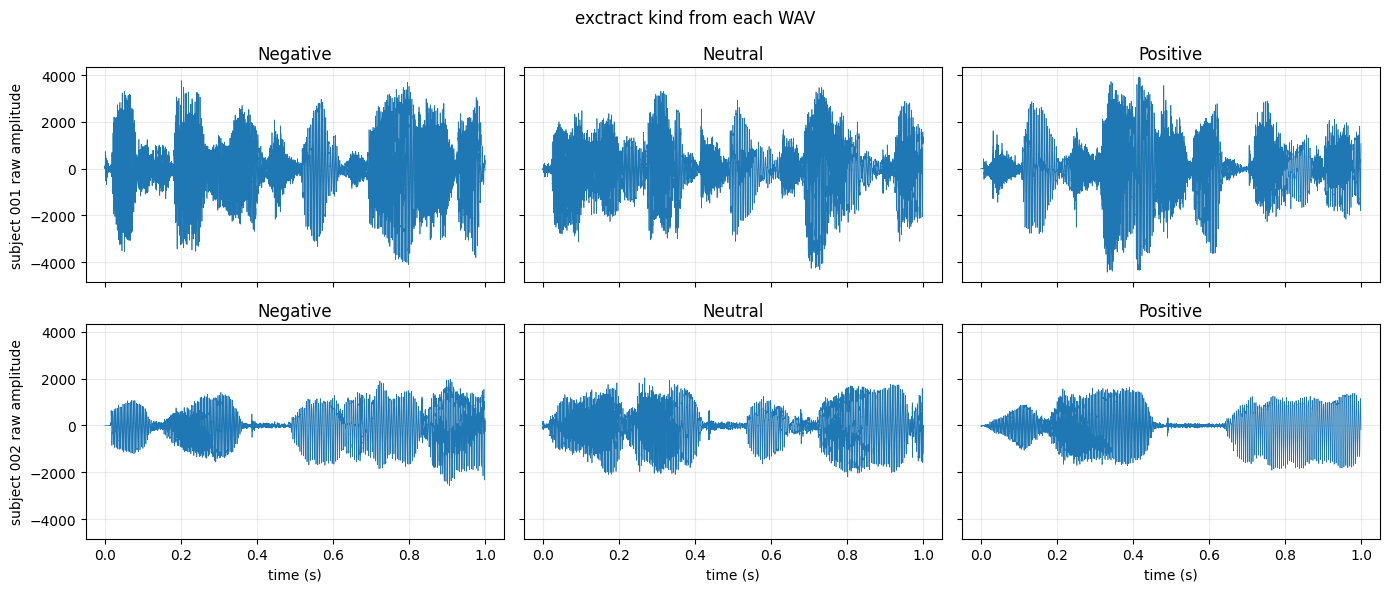

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=True)
for row, subject in enumerate(subjects):

    for col, value in enumerate(values):

        fs, raw = wavfile.read(wav_files[(subject, value)])
        channels = 1 if raw.ndim == 1 else raw.shape[1]

        print(f'{subject} / {value}: {fs} Hz, {channels} channels, {raw.dtype}, shape {raw.shape}, {len(raw)/fs:.2f} s')

        mono = raw.mean(axis=1) if channels == 2 else raw

        start, stop = int(0 * fs), min(int(1 * fs), len(mono))

        time = np.arange(start, stop) / fs
        ax = axes[row, col]
        ax.plot(time, mono[start:stop], linewidth=0.5)
        ax.set_title(value.title())
        ax.grid(alpha=0.25)

    axes[row, 0].set_ylabel(f'subject {subject} raw amplitude')

for ax in axes[-1]:
    ax.set_xlabel('time (s)')
fig.suptitle('exctract kind from each WAV')
plt.tight_layout()
plt.show()

#**3.	OOP for data processing**

In [ ]:
class SpeechRecording:

    def __init__(self, filename):
        self.fs, samples = wavfile.read(filename)
        source_dtype = samples.dtype

        if samples.ndim == 2:  # stereo to mono
            samples = samples.mean(axis=1)

        self.samples = samples.astype(float)
        if np.issubdtype(source_dtype, np.integer): #normalization
            self.samples /= max(abs(np.iinfo(source_dtype).min), np.iinfo(source_dtype).max)

    def first_seconds(self, seconds=3):
        x = self.samples[:int(seconds * self.fs)]
        return x - np.mean(x)  #DC component removal

class SignalAnalyzer:

    def __init__(self, samples, fs):
        self.x = samples
        self.fs = fs

    def rms(self):
        return np.sqrt(np.mean(self.x ** 2))

    def envelope(self, window_ms=20):
        width = max(1, int(self.fs * window_ms / 1000))
        return np.convolve(np.abs(self.x), np.ones(width) / width, mode='same')

    def envelope_derivative(self, window_ms=20):
        return np.diff(self.envelope(window_ms)) * self.fs  #Δamplitude/Δtime

#**4.	Numerical derivation or integration of data**

/tmp/ipykernel_956/2895653613.py:4: WavFileWarning: Reached EOF prematurely; finished at 862200 bytes, expected 862204 bytes from header.
  self.fs, samples = wavfile.read(filename)


Sample rate: 48000 Hz
Duration analyzed: 3.00 s
RMS amplitude: 0.0259


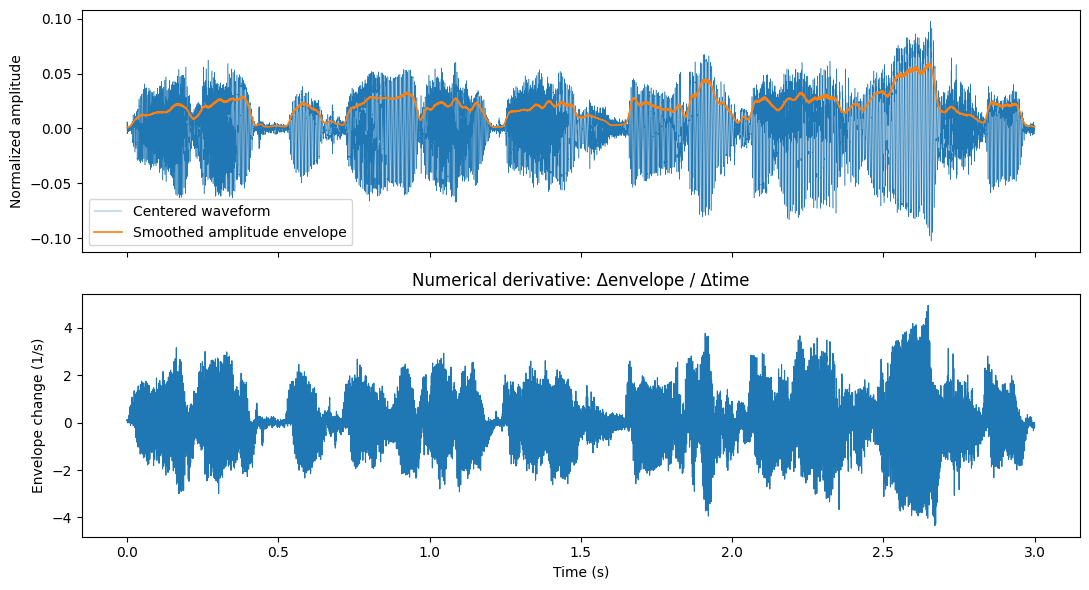

In [ ]:
audio_file = wav_files[('002', 'neutral')]

recording = SpeechRecording(audio_file)

x = recording.first_seconds(3)

analyzer = SignalAnalyzer(x, recording.fs)

t = np.arange(len(x)) / recording.fs

envelope = analyzer.envelope()
derivative = analyzer.envelope_derivative()

print(f'Sample rate: {recording.fs} Hz')
print(f'Duration analyzed: {len(x) / recording.fs:.2f} s')
print(f'RMS amplitude: {analyzer.rms():.4f}')

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

axes[0].plot(t, x, linewidth=0.35, label='Centered waveform')
axes[0].plot(t, envelope, linewidth=1.2, label='smoothed amplitude envelope')
axes[0].set_ylabel('Normalized amplitude')
axes[0].legend()
axes[1].plot(t[1:], derivative, linewidth=0.8)
axes[1].set_xlabel('time (s)')
axes[1].set_ylabel('envelope change (1/s)')
axes[1].set_title('numerical derivative: Δenvelope/Δtime')
plt.tight_layout()
plt.show()

In [ ]:
matrix = np.stack([x[i * recording.fs:(i+1) * recording.fs] for i in range(3)])

tensor = np.stack((matrix, np.abs(matrix)), axis=-1)
rms_per_second = np.sqrt(np.mean(matrix ** 2, axis=1))
peak_per_second = np.max(np.abs(matrix), axis=1)

print('vector shape:', x.shape)
print('matrix shape (seconds × n):', matrix.shape)
print('tensor shape (seconds × n × channels):', tensor.shape)
print("RMS:", rms_per_second)
print("Peak amplitude:", peak_per_second)

vector shape: (144000,)
matrix shape (seconds × n): (3, 48000)
tensor shape (seconds × n × channels): (3, 48000, 2)
RMS: [0.02195446 0.02321144 0.03151014]
Peak amplitude: [0.06636671 0.08083205 0.10289626]


#**discussion**
The six raw excerpts show waveform amplitude from two participants performing picture-description tasks. Even if the waveforms differ visually, this small example cannot attribute changes to clinical status or picture valence. For the neutral recording of participant 002, centering removes the constant offset, the 20 ms moving average of absolute amplitude highlights broader signal changes, and the derivative shows where this envelope rises or falls. RMS summarizes average amplitude; it is not a clinical measure. The short-time RMS curves and spectrograms show how level and frequency content vary over time, but differences across these two recordings also depend on speech content and recording conditions.
#**conclusions**
The variation within one recording suggests that speech amplitude is best considered as a changing signal rather than a single value. The analysis show that those can be measured with simple numerical methods, but it provides no evidence that RMS or the envelope derivative distinguishes depressive symptoms.
#**AI models declaration**
AI (chatgpt) was used as an assistance tool in the next tasks:

consulting functions or methods documetation for specific tasks

Providing suggestions for data analysis or visualization approaches

orthography corrections and recoemndations in structure